In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 28.6 MB/s eta 0:00:00


## load CIFAR10 data from kaggle

In [ ]:
import os
from google.colab import files

# 1. Upload your kaggle.json file
uploaded = files.upload()

# 2. Create the ~/.kaggle directory if it doesn't exist
os.makedirs('/root/.kaggle', exist_ok=True)

# 3. Move the uploaded kaggle.json file to ~/.kaggle/
!mv kaggle.json /root/.kaggle/

# 4. Set appropriate file permissions (read/write for owner only)
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle API key configured successfully!")

Saving kaggle_api.json to kaggle_api.json
mv: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Kaggle API key configured successfully!


In [ ]:
# Install Kaggle library if not already installed
!pip install -q kaggle

# Download the dataset (replace with your dataset's API command)
!kaggle datasets download -d fedesoriano/cifar10-python-in-csv

# Unzip the downloaded dataset into a specific directory
import zipfile

dataset_zip = "cifar10-python-in-csv.zip"  # Replace with the actual zip filename downloaded

with zipfile.ZipFile(dataset_zip, 'r') as zip_ref:
    zip_ref.extractall('dataset_folder')

print("Dataset downloaded and extracted!")

Dataset URL: https://www.kaggle.com/datasets/fedesoriano/cifar10-python-in-csv
License(s): copyright-authors
100% 209M/209M [00:02<00:00, 90.9MB/s]

Dataset downloaded and extracted!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import optuna

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available()  else "cpu")
device

device(type='cuda')

In [ ]:
#load data from csv
train = pd.read_csv('dataset_folder/train.csv')
test = pd.read_csv('dataset_folder/test.csv')

In [ ]:
train.shape, test.shape

((50000, 3073), (10000, 3072))

In [ ]:
x_train = train.iloc[:, :-1]
y_train = train.iloc[:, -1]
x_test = test.copy()

In [ ]:
x_train.shape, y_train.shape, x_test.shape

((50000, 3072), (50000,), (10000, 3072))

### since test dataset does not have the target values, we need a validation set from training set


In [ ]:
#since test dataset does not have the target values, we need a validation set from training set
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=10000, random_state = 3)

In [ ]:
x_train.shape, x_val.shape, y_train.shape, y_val.shape

((40000, 3072), (10000, 3072), (40000,), (10000,))

In [ ]:
x_train.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3062,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071
6061,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.996078,0.996078,0.996078,0.996078,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
13906,0.560784,0.517647,0.600000,0.568627,0.592157,0.662745,0.631373,0.776471,0.486275,0.505882,...,0.305882,0.290196,0.286275,0.286275,0.262745,0.258824,0.290196,0.333333,0.341176,0.345098
19664,0.584314,0.592157,0.603922,0.615686,0.627451,0.635294,0.643137,0.650980,0.654902,0.658824,...,0.298039,0.294118,0.294118,0.290196,0.290196,0.286275,0.282353,0.270588,0.266667,0.262745
16830,0.768627,0.756863,0.792157,0.815686,0.843137,0.858824,0.866667,0.862745,0.815686,0.792157,...,0.552941,0.580392,0.596078,0.596078,0.600000,0.576471,0.552941,0.549020,0.549020,0.541176
16916,0.549020,0.525490,0.521569,0.494118,0.466667,0.501961,0.580392,0.607843,0.607843,0.572549,...,0.007843,0.007843,0.003922,0.000000,0.000000,0.007843,0.011765,0.007843,0.003922,0.003922


- The images are organized as 3 x 32 x 32 (commonly used format in pytorch)
- 3 channels (RGB), 32 height and 32 width

In [ ]:
y_train.head()

,label
6061,3
13906,9
19664,0
16830,8
16916,6


In [ ]:
#This dictionary will help us map the integers in target to their respective category
class_map = {
    0: "airplane",
    1: "automobile",
    2: "bird",
    3: "cat",
    4: "deer",
    5: "dog",
    6: "frog",
    7: "horse",
    8: "ship",
    9: "truck"
}

In [ ]:
classes = y_train.value_counts().sort_index()
classes.index = class_map.values()
classes

,count
airplane,3968
automobile,4049
bird,3967
cat,4006
deer,4082
dog,3994
frog,3957
horse,3960
ship,4030
truck,3987


The classes are balanced. So, we may use accuracy as a reliable metric while training our model.

let's see one image

TypeError: Invalid shape (3, 32, 32) for image data

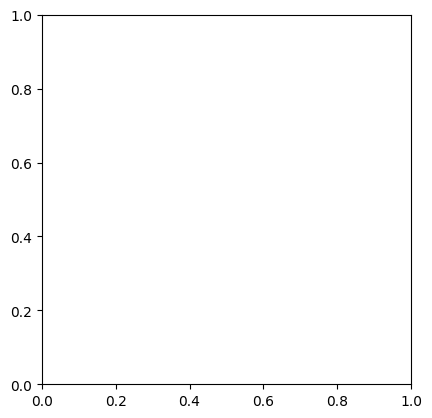

In [ ]:
plt.imshow(x_train.iloc[2].values.reshape(3, 32, 32))
plt.show()

We are getting this error because the `imshow` method needs the image in the format 32x32x3

This format is commonly used in OpenCV

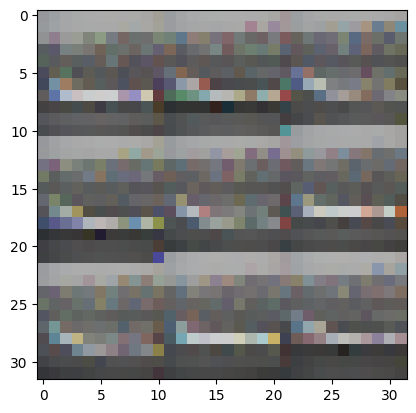

In [ ]:
plt.imshow(x_train.iloc[2].values.reshape(32, 32, 3))
plt.show()

In [ ]:
#What is this image?
class_map[y_train.iloc[2]]

'airplane'

That's an airplane image, but we are getting 9 such images in one plot.

So this is not the correct way of reorganizing the height, width, or channels of an image.

we need to use numpy's `transpose` or pytorch's `permute` method because we need to transpose the axes, not just alter the shape structure.

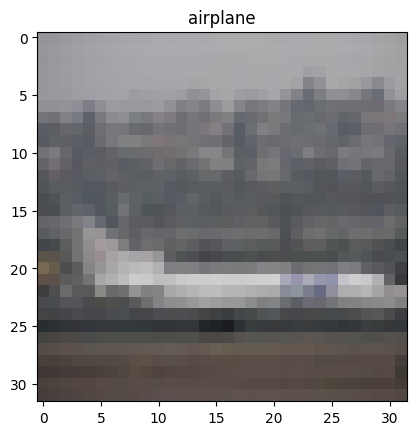

In [ ]:
plt.imshow(x_train.iloc[2].values.reshape(3, 32, 32).transpose(1, 2, 0))
                              # positions 0   1   2           (h, w, channel)
plt.title(class_map[y_train.iloc[2]])
plt.show()

Create the `Dataset` and `DataLoader` class to work with batches of data

In [ ]:
#create a dataset class to fetch the image as 3x32x32 tensors
class d_set(Dataset):

  def __init__(self, x: np.ndarray, y: np.ndarray):

    self.x = torch.tensor(x, dtype = torch.float)  #convert to float tensor
    self.y = torch.tensor(y, dtype=torch.long)     #convert to integer tensor (required for CE loss)

  def __getitem__(self, index):
    return self.x[index].reshape(3, 32, 32), self.y[index]
                # gives one 3x32x32 image and its integer target

  def __len__(self):
    return self.x.shape[0]

In [ ]:
#initialize the class separately for train and validation sets
train_set = d_set(x_train.values, y_train.values)
val_set = d_set(x_val.values, y_val.values)

In [ ]:
#Number of samples in each set
len(train_set), len(val_set)

(40000, 10000)

In [ ]:
sample_datapoint = train_set[0]
sample_datapoint[0].shape , sample_datapoint[1]
# image                           target

(torch.Size([3, 32, 32]), tensor(3))

In [ ]:
#iterable dataloaders
train_loader = DataLoader(train_set, batch_size=128, shuffle = True)  #shuffle at the start of each epoch
val_loader = DataLoader(val_set, batch_size=128, shuffle = True)  #shuffle at the start of each epoch

The dataloaders will give n images as n x 3 x 32 x 32.

n = 128 (number of images in a batch).

In [ ]:
for images, targets in train_loader:
  print(images.shape)
  print(targets.shape)
  break

torch.Size([128, 3, 32, 32])
torch.Size([128])


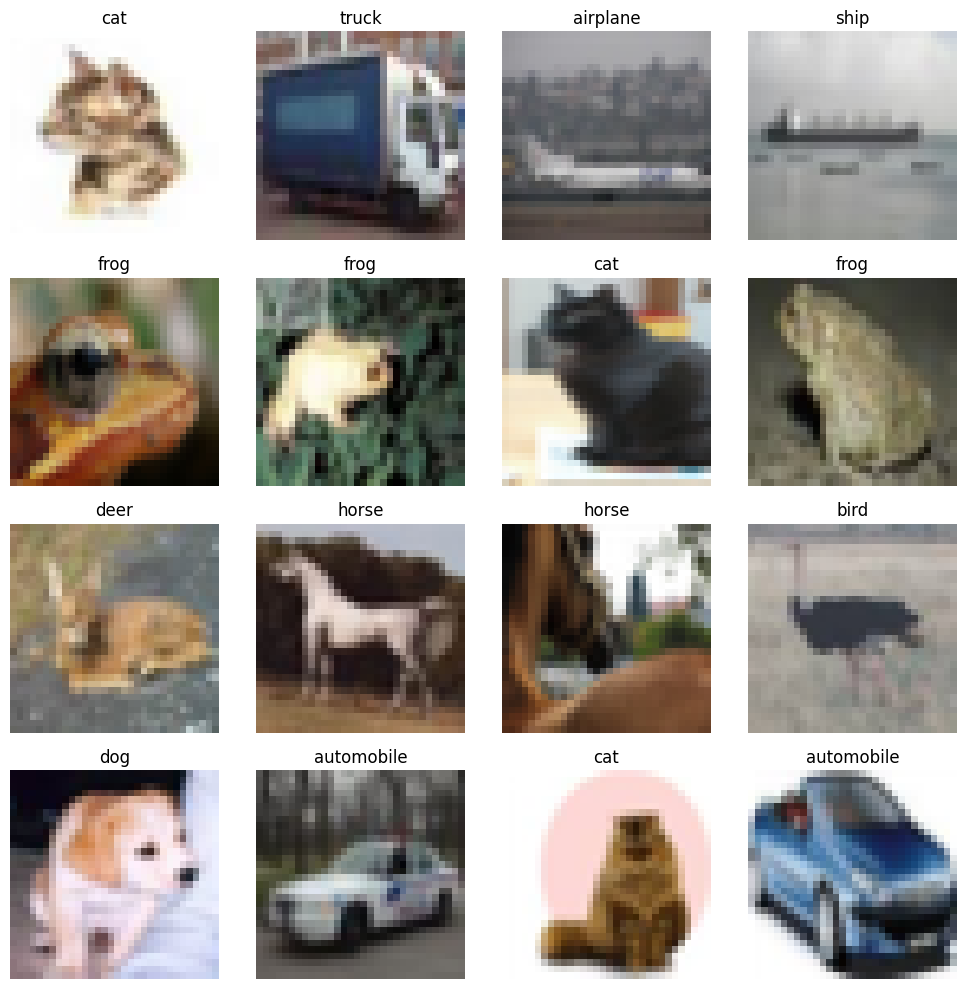

In [ ]:
#Plot a few images from training set.
plt.figure(figsize = (10, 10))
for i in range(16):
  plt.subplot(4,4, i+1)
  plt.imshow(train_set[i][0].permute(1, 2, 0))
  plt.title(f"{class_map[train_set[i][1].item()]}")
  plt.axis('off')
plt.tight_layout()
plt.show()


Build a simple CNN architecture using `nn.Module`

In [ ]:
class CNN(nn.Module):

  def __init__(self, in_channels):
    super().__init__()

      # define architecture
    self.feature_layer = nn.Sequential(
        #input requires 'n' images as (n, channel, height, width)


        nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=3, padding = "same"),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding = "same"),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)
    )

    self.classif_layer = nn.Sequential(
        nn.Flatten(),

        nn.Linear(8*8*64, 784),
        nn.ReLU(),

        nn.Linear(784, 196),
        nn.ReLU(),

        nn.Linear(196, 10),
        #output logits
    )

  def forward(self, x):
    features = self.feature_layer(x)  #conv layer
    output = self.classif_layer(features) #output layer
    return output

# Training

In [ ]:
model = CNN(3)
model = model.to(device)
lr = 0.001
optim = torch.optim.Adam(model.parameters(), lr = lr)
loss_func = nn.CrossEntropyLoss()

In [ ]:
def train_model(model, optim):
  model.train()
  train_loss = 0.0

  for batch_x, batch_y in train_loader:
      # Move data to GPU
      batch_x, batch_y = batch_x.to(device), batch_y.to(device)

      # Forward pass
      y_pred = model(batch_x)
      loss = loss_func(y_pred, batch_y)

      # Backward propagation
      optim.zero_grad()
      loss.backward()

      # Update weights
      optim.step()

      train_loss += loss.item()

  avg_train_loss = train_loss / len(train_loader)
  return avg_train_loss

1. Without early stopping

In [ ]:
# train loop
epochs = 40
for e in range(epochs):
  avg_train_loss = train_model(model, optim)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f}")

Epoch 01/40 | Train Loss: 1.6188
Epoch 02/40 | Train Loss: 1.2281
Epoch 03/40 | Train Loss: 1.0310
Epoch 04/40 | Train Loss: 0.8935
Epoch 05/40 | Train Loss: 0.7775
Epoch 06/40 | Train Loss: 0.6707
Epoch 07/40 | Train Loss: 0.5606
Epoch 08/40 | Train Loss: 0.4521
Epoch 09/40 | Train Loss: 0.3455
Epoch 10/40 | Train Loss: 0.2449
Epoch 11/40 | Train Loss: 0.1776
Epoch 12/40 | Train Loss: 0.1186
Epoch 13/40 | Train Loss: 0.0948
Epoch 14/40 | Train Loss: 0.0697
Epoch 15/40 | Train Loss: 0.0664
Epoch 16/40 | Train Loss: 0.0451
Epoch 17/40 | Train Loss: 0.0575
Epoch 18/40 | Train Loss: 0.0521
Epoch 19/40 | Train Loss: 0.0611
Epoch 20/40 | Train Loss: 0.0543
Epoch 21/40 | Train Loss: 0.0484
Epoch 22/40 | Train Loss: 0.0276
Epoch 23/40 | Train Loss: 0.0394
Epoch 24/40 | Train Loss: 0.0389
Epoch 25/40 | Train Loss: 0.0422
Epoch 26/40 | Train Loss: 0.0367
Epoch 27/40 | Train Loss: 0.0374
Epoch 28/40 | Train Loss: 0.0317
Epoch 29/40 | Train Loss: 0.0358
Epoch 30/40 | Train Loss: 0.0305
Epoch 31/4

In [ ]:
# Function to evaluate model accuracy
def eval_model(model, loader, return_labels = False):
  model.eval()
  with torch.no_grad():
    total = 0
    correct = 0
    predictions = []
    true_label = []

    for batch_x, batch_y in loader:

      batch_x, batch_y = batch_x.to(device), batch_y.to(device)
      true_label.extend(batch_y.tolist())

      y_pred = model(batch_x)
      predictions = y_pred.max(axis = 1)[1]

      total = total + batch_x.shape[0]
      correct += (predictions == batch_y).sum().item()

  accuracy = correct / total

  if return_labels:
    return accuracy, true_label, predictions

  return accuracy

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

train accuracy -> 0.9882
validation accuracy -> 0.6883


- This is highly overfitting

2. Using early stopping to prevent overfitting and save time

In [ ]:
model = CNN(3)
model = model.to(device)
lr = 0.001
optim = torch.optim.Adam(model.parameters(), lr = lr)
loss_func = nn.CrossEntropyLoss()

# for Early Stopping
patience = 5
patience_counter = 0
best_val_loss = float('inf')
best_model_weights = None

# train loop
epochs = 40
for e in range(epochs):

  # ------------------ TRAINING PHASE ------------------
  avg_train_loss = train_model(model, optim)

  # ------------------ VALIDATION PHASE ------------------

  model.eval()
  val_loss = 0.0

  with torch.no_grad():
      for batch_x, batch_y in val_loader:
          batch_x, batch_y = batch_x.to(device), batch_y.to(device)
          y_pred = model(batch_x)
          loss = loss_func(y_pred, batch_y)
          val_loss += loss.item()

  avg_val_loss = val_loss / len(val_loader)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

  # Early stopping logic
  if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      patience_counter = 0
      # Save the best model parameters
      best_model_weights = model.state_dict().copy()
      print(f"--> Val loss improved! Saving best weights.")
  else:
      patience_counter += 1
      print(f"--> No improvement in val loss ({patience_counter}/{patience})")

  if patience_counter >= patience:
      print(f"\n[Early Stopping Triggered] Stopped early at epoch {e+1}.")
      break

# Restore best weights after training stops
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Loaded best model weights into model!")

Epoch 01/40 | Train Loss: 1.6170 | Val Loss: 1.3224
--> Val loss improved! Saving best weights.
Epoch 02/40 | Train Loss: 1.2014 | Val Loss: 1.1050
--> Val loss improved! Saving best weights.
Epoch 03/40 | Train Loss: 1.0039 | Val Loss: 1.0081
--> Val loss improved! Saving best weights.
Epoch 04/40 | Train Loss: 0.8637 | Val Loss: 0.9632
--> Val loss improved! Saving best weights.
Epoch 05/40 | Train Loss: 0.7475 | Val Loss: 0.9203
--> Val loss improved! Saving best weights.
Epoch 06/40 | Train Loss: 0.6370 | Val Loss: 0.8860
--> Val loss improved! Saving best weights.
Epoch 07/40 | Train Loss: 0.5181 | Val Loss: 0.9252
--> No improvement in val loss (1/5)
Epoch 08/40 | Train Loss: 0.4043 | Val Loss: 0.9881
--> No improvement in val loss (2/5)
Epoch 09/40 | Train Loss: 0.3020 | Val Loss: 1.0666
--> No improvement in val loss (3/5)
Epoch 10/40 | Train Loss: 0.2149 | Val Loss: 1.1349
--> No improvement in val loss (4/5)
Epoch 11/40 | Train Loss: 0.1387 | Val Loss: 1.3469
--> No improveme

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

train accuracy -> 0.967375
validation accuracy -> 0.6952


- Early stopping reduced overfitting slightly
- and also saved both our time and compute resources.

Let's see how we can reduce further overfitting

use batch normalization, dropout, weight decay for better regularization and more stable training.

3. Using Batch Normalization, Dropout and weight decay

In [ ]:
class CNN_2(nn.Module):

  def __init__(self, in_channels):
    super().__init__()
    self.feature_layer = nn.Sequential(
        nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)
    )

    self.classif_layer = nn.Sequential(
        nn.Flatten(),

        nn.Linear(8*8*64, 784),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(784, 196),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(196, 10),
    )

  def forward(self, x):
    features = self.feature_layer(x)
    output = self.classif_layer(features)
    return output

In [ ]:
model = CNN_2(3)
model = model.to(device)
lr = 0.001
optim = torch.optim.Adam(model.parameters(), lr = lr, weight_decay = 5e-4)
loss_func = nn.CrossEntropyLoss()

# for Early Stopping
patience = 5
patience_counter = 0
best_val_loss = float('inf')
best_model_weights = None

# train loop
epochs = 40
for e in range(epochs):

  # ------------------ TRAINING PHASE ------------------
  avg_train_loss = train_model(model, optim)

  # ------------------ VALIDATION PHASE ------------------

  model.eval()
  val_loss = 0.0

  with torch.no_grad():
      for batch_x, batch_y in val_loader:
          batch_x, batch_y = batch_x.to(device), batch_y.to(device)
          y_pred = model(batch_x)
          loss = loss_func(y_pred, batch_y)
          val_loss += loss.item()

  avg_val_loss = val_loss / len(val_loader)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

  # Early stopping logic
  if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      patience_counter = 0
      # Save the best model parameters
      best_model_weights = model.state_dict().copy()
      print(f"--> Val loss improved! Saving best weights.")
  else:
      patience_counter += 1
      print(f"--> No improvement in val loss ({patience_counter}/{patience})")

  if patience_counter >= patience:
      print(f"\n[Early Stopping Triggered] Stopped early at epoch {e+1}.")
      break

# Restore best weights after training stops
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Loaded best model weights into model!")

Epoch 01/40 | Train Loss: 1.4839 | Val Loss: 1.6110
--> Val loss improved! Saving best weights.
Epoch 02/40 | Train Loss: 1.0844 | Val Loss: 1.0741
--> Val loss improved! Saving best weights.
Epoch 03/40 | Train Loss: 0.9482 | Val Loss: 0.8748
--> Val loss improved! Saving best weights.
Epoch 04/40 | Train Loss: 0.8522 | Val Loss: 0.9147
--> No improvement in val loss (1/5)
Epoch 05/40 | Train Loss: 0.7874 | Val Loss: 0.9537
--> No improvement in val loss (2/5)
Epoch 06/40 | Train Loss: 0.7219 | Val Loss: 0.8634
--> Val loss improved! Saving best weights.
Epoch 07/40 | Train Loss: 0.6692 | Val Loss: 0.9493
--> No improvement in val loss (1/5)
Epoch 08/40 | Train Loss: 0.6161 | Val Loss: 0.9123
--> No improvement in val loss (2/5)
Epoch 09/40 | Train Loss: 0.5748 | Val Loss: 0.9109
--> No improvement in val loss (3/5)
Epoch 10/40 | Train Loss: 0.5288 | Val Loss: 0.7503
--> Val loss improved! Saving best weights.
Epoch 11/40 | Train Loss: 0.4805 | Val Loss: 0.7958
--> No improvement in v

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

train accuracy -> 0.904575
validation accuracy -> 0.7389


That's a significant improvement in model performance.
better generalization, reduced overfitting

But there is still some room left to bring down overfitting.

my hypothesis:

- reducing the pooling layer may help here because the image size is already very small (32,32), and reducing it further by pooling will certainly result in loss of important information from an already low resolution image.

- generally the classification layer shouldn't be too complex,
because the convolutional layers have already extracted meaningful features from the images.
try reducing the complexity of the classification layer and see if there is any improvement


let's try removing pooling layer

In [ ]:
class CNN_3(nn.Module):

  def __init__(self, in_channels):
    super().__init__()
    self.feature_layer = nn.Sequential(
        nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(32),
        nn.ReLU(),

        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(64),
        nn.ReLU()
    )

    self.classif_layer = nn.Sequential(
        nn.Flatten(),

        nn.Linear(32*32*64, 784),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(784, 196),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(196, 10),
    )

  def forward(self, x):
    features = self.feature_layer(x)
    output = self.classif_layer(features)
    return output

In [ ]:
model = CNN_3(3)
model = model.to(device)
lr = 0.001
optim = torch.optim.Adam(model.parameters(), lr = lr, weight_decay = 5e-4)
loss_func = nn.CrossEntropyLoss()

# for Early Stopping
patience = 5
patience_counter = 0
best_val_loss = float('inf')
best_model_weights = None

# train loop
epochs = 50
for e in range(epochs):

  # ------------------ TRAINING PHASE ------------------
  avg_train_loss = train_model(model, optim)

  # ------------------ VALIDATION PHASE ------------------

  model.eval()
  val_loss = 0.0

  with torch.no_grad():
      for batch_x, batch_y in val_loader:
          batch_x, batch_y = batch_x.to(device), batch_y.to(device)
          y_pred = model(batch_x)
          loss = loss_func(y_pred, batch_y)
          val_loss += loss.item()

  avg_val_loss = val_loss / len(val_loader)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

  # Early stopping logic
  if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      patience_counter = 0
      # Save the best model parameters
      best_model_weights = model.state_dict().copy()
      print(f"--> Val loss improved! Saving best weights.")
  else:
      patience_counter += 1
      print(f"--> No improvement in val loss ({patience_counter}/{patience})")

  if patience_counter >= patience:
      print(f"\n[Early Stopping Triggered] Stopped early at epoch {e+1}.")
      break

# Restore best weights after training stops
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Loaded best model weights into model!")

Epoch 01/50 | Train Loss: 1.7594 | Val Loss: 1.3809
--> Val loss improved! Saving best weights.
Epoch 02/50 | Train Loss: 1.2611 | Val Loss: 1.2138
--> Val loss improved! Saving best weights.
Epoch 03/50 | Train Loss: 1.0938 | Val Loss: 1.1455
--> Val loss improved! Saving best weights.
Epoch 04/50 | Train Loss: 0.9979 | Val Loss: 1.0373
--> Val loss improved! Saving best weights.
Epoch 05/50 | Train Loss: 0.9283 | Val Loss: 1.0711
--> No improvement in val loss (1/5)
Epoch 06/50 | Train Loss: 0.8568 | Val Loss: 0.9798
--> Val loss improved! Saving best weights.
Epoch 07/50 | Train Loss: 0.7964 | Val Loss: 1.0064
--> No improvement in val loss (1/5)
Epoch 08/50 | Train Loss: 0.7239 | Val Loss: 1.1765
--> No improvement in val loss (2/5)
Epoch 09/50 | Train Loss: 0.6754 | Val Loss: 0.9369
--> Val loss improved! Saving best weights.
Epoch 10/50 | Train Loss: 0.6077 | Val Loss: 1.1304
--> No improvement in val loss (1/5)
Epoch 11/50 | Train Loss: 0.5516 | Val Loss: 1.0186
--> No improveme

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

train accuracy -> 0.86975
validation accuracy -> 0.6408


completely removing pooling resulted in performance drop.
So, we will use the pooling layers

Next, let's try to reduce the complexity of the classification layer.

In [ ]:
class CNN_4(nn.Module):

  def __init__(self, in_channels):
    super().__init__()
    self.feature_layer = nn.Sequential(
        nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)

    )

    self.classif_layer = nn.Sequential(
        nn.Flatten(),

        nn.Linear(8*8*64, 512),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(512, 10),
    )

  def forward(self, x):
    features = self.feature_layer(x)
    output = self.classif_layer(features)
    return output

In [ ]:
model = CNN_4(3)
model = model.to(device)
lr = 0.001
optim = torch.optim.Adam(model.parameters(), lr = lr, weight_decay = 5e-4)
loss_func = nn.CrossEntropyLoss()

# for Early Stopping
patience = 5
patience_counter = 0
best_val_loss = float('inf')
best_model_weights = None

# train loop
epochs = 50
for e in range(epochs):

  # ------------------ TRAINING PHASE ------------------
  avg_train_loss = train_model(model, optim)

  # ------------------ VALIDATION PHASE ------------------

  model.eval()
  val_loss = 0.0

  with torch.no_grad():
      for batch_x, batch_y in val_loader:
          batch_x, batch_y = batch_x.to(device), batch_y.to(device)
          y_pred = model(batch_x)
          loss = loss_func(y_pred, batch_y)
          val_loss += loss.item()

  avg_val_loss = val_loss / len(val_loader)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

  # Early stopping logic
  if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      patience_counter = 0
      # Save the best model parameters
      best_model_weights = model.state_dict().copy()
      print(f"--> Val loss improved! Saving best weights.")
  else:
      patience_counter += 1
      print(f"--> No improvement in val loss ({patience_counter}/{patience})")

  if patience_counter >= patience:
      print(f"\n[Early Stopping Triggered] Stopped early at epoch {e+1}.")
      break

# Restore best weights after training stops
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Loaded best model weights into model!")

Epoch 01/50 | Train Loss: 1.4958 | Val Loss: 1.1594
--> Val loss improved! Saving best weights.
Epoch 02/50 | Train Loss: 1.0697 | Val Loss: 1.1116
--> Val loss improved! Saving best weights.
Epoch 03/50 | Train Loss: 0.9368 | Val Loss: 0.9419
--> Val loss improved! Saving best weights.
Epoch 04/50 | Train Loss: 0.8392 | Val Loss: 0.8849
--> Val loss improved! Saving best weights.
Epoch 05/50 | Train Loss: 0.7850 | Val Loss: 0.8471
--> Val loss improved! Saving best weights.
Epoch 06/50 | Train Loss: 0.7268 | Val Loss: 0.8873
--> No improvement in val loss (1/5)
Epoch 07/50 | Train Loss: 0.6819 | Val Loss: 0.8072
--> Val loss improved! Saving best weights.
Epoch 08/50 | Train Loss: 0.6349 | Val Loss: 0.8193
--> No improvement in val loss (1/5)
Epoch 09/50 | Train Loss: 0.5946 | Val Loss: 0.9206
--> No improvement in val loss (2/5)
Epoch 10/50 | Train Loss: 0.5623 | Val Loss: 0.7481
--> Val loss improved! Saving best weights.
Epoch 11/50 | Train Loss: 0.5185 | Val Loss: 0.8522
--> No im

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

train accuracy -> 0.914825
validation accuracy -> 0.7516


- This performs slightly better !!

Let's add more convolution layer

In [ ]:
class CNN_5(nn.Module):

  def __init__(self, in_channels):
    super().__init__()
    self.feature_layer = nn.Sequential(
        nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )

    self.classif_layer = nn.Sequential(
        nn.Flatten(),

        nn.Linear(4*4*128, 512),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(512, 10),
    )

  def forward(self, x):
    features = self.feature_layer(x)
    output = self.classif_layer(features)
    return output

In [ ]:
model = CNN_5(3)
model = model.to(device)
lr = 0.001
optim = torch.optim.Adam(model.parameters(), lr = lr, weight_decay = 5e-4)
loss_func = nn.CrossEntropyLoss()

# for Early Stopping
patience = 5
patience_counter = 0
best_val_loss = float('inf')
best_model_weights = None

# train loop
epochs = 50
for e in range(epochs):

  # ------------------ TRAINING PHASE ------------------
  avg_train_loss = train_model(model, optim)

  # ------------------ VALIDATION PHASE ------------------

  model.eval()
  val_loss = 0.0

  with torch.no_grad():
      for batch_x, batch_y in val_loader:
          batch_x, batch_y = batch_x.to(device), batch_y.to(device)
          y_pred = model(batch_x)
          loss = loss_func(y_pred, batch_y)
          val_loss += loss.item()

  avg_val_loss = val_loss / len(val_loader)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

  # Early stopping logic
  if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      patience_counter = 0
      # Save the best model parameters
      best_model_weights = model.state_dict().copy()
      print(f"--> Val loss improved! Saving best weights.")
  else:
      patience_counter += 1
      print(f"--> No improvement in val loss ({patience_counter}/{patience})")

  if patience_counter >= patience:
      print(f"\n[Early Stopping Triggered] Stopped early at epoch {e+1}.")
      break

# Restore best weights after training stops
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Loaded best model weights into model!")

Epoch 01/50 | Train Loss: 1.3856 | Val Loss: 1.0547
--> Val loss improved! Saving best weights.
Epoch 02/50 | Train Loss: 0.9752 | Val Loss: 1.0293
--> Val loss improved! Saving best weights.
Epoch 03/50 | Train Loss: 0.8280 | Val Loss: 0.8149
--> Val loss improved! Saving best weights.
Epoch 04/50 | Train Loss: 0.7303 | Val Loss: 0.8994
--> No improvement in val loss (1/5)
Epoch 05/50 | Train Loss: 0.6534 | Val Loss: 0.7968
--> Val loss improved! Saving best weights.
Epoch 06/50 | Train Loss: 0.5941 | Val Loss: 0.9538
--> No improvement in val loss (1/5)
Epoch 07/50 | Train Loss: 0.5437 | Val Loss: 1.1782
--> No improvement in val loss (2/5)
Epoch 08/50 | Train Loss: 0.4919 | Val Loss: 0.7539
--> Val loss improved! Saving best weights.
Epoch 09/50 | Train Loss: 0.4451 | Val Loss: 0.7248
--> Val loss improved! Saving best weights.
Epoch 10/50 | Train Loss: 0.4071 | Val Loss: 0.7855
--> No improvement in val loss (1/5)
Epoch 11/50 | Train Loss: 0.3701 | Val Loss: 0.7041
--> Val loss imp

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")

train accuracy -> 0.95525
validation accuracy -> 0.7766


Overfitting is still there but this is by far our best model.

Hyperparameter tuning to squeeze out extra performance

In [ ]:
class CNN_tune(nn.Module):

  def __init__(self, in_channels, dropout, neurons):
    super().__init__()
    self.feature_layer = nn.Sequential(
        nn.Conv2d(in_channels=in_channels, out_channels=32, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding = "same"),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )

    self.classif_layer = nn.Sequential(
        nn.Flatten(),

        nn.Linear(4*4*128, neurons),
        nn.ReLU(),
        nn.Dropout(dropout),

        nn.Linear(neurons, 10),
    )

  def forward(self, x):
    features = self.feature_layer(x)
    output = self.classif_layer(features)
    return output

In [ ]:
# To speed up hyperparameter tuning

train_loader = DataLoader(
    train_set,
    batch_size=256,  # Slightly increasing batch size (128 -> 256) speeds up GPU compute
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_set,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
def objective(trial):

  regularization = trial.suggest_float('regularization', 1e-6, 1e-3, log = True)
  dropout = trial.suggest_float('dropout', 0.1, 0.5)
  neurons = trial.suggest_categorical('neurons', [128, 256, 512])
  lr = trial.suggest_float('lr', 1e-4, 1e-2, log = True)

  model = CNN_tune(3, dropout, neurons).to(device)
  loss_func = nn.CrossEntropyLoss()
  optimizer_adam = torch.optim.Adam(model.parameters(), lr = lr, weight_decay = regularization)

  # for Early Stopping
  patience = 5
  patience_counter = 0
  best_val_loss = float('inf')
  best_model_weights = None

  # train loop
  epochs = 50
  for e in range(epochs):

    # ------------------ TRAINING PHASE ------------------
    avg_train_loss = train_model(model, optimizer_adam)

    # ------------------ VALIDATION PHASE ------------------

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            y_pred = model(batch_x)
            loss = loss_func(y_pred, batch_y)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    # Early stopping logic
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print(f"break at epoch: {e}")
        break

  return best_val_loss


In [ ]:
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials = 25)

[I 2026-10-08 05:40:42,767] A new study created in memory with name: no-name-df397d99-5a82-4865-94e3-efa8f00d8edc
[I 2026-10-08 05:42:05,219] Trial 0 finished with value: 0.7390800580382347 and parameters: {'regularization': 0.0007406182101358744, 'dropout': 0.36890773418685574, 'neurons': 512, 'lr': 0.0017933017439078903}. Best is trial 0 with value: 0.7390800580382347.


break at epoch: 16


[I 2026-10-08 05:43:15,922] Trial 1 finished with value: 0.7050647683441639 and parameters: {'regularization': 4.551164390579541e-05, 'dropout': 0.3312275892512391, 'neurons': 128, 'lr': 0.0011711828606204811}. Best is trial 1 with value: 0.7050647683441639.


break at epoch: 14


[I 2026-10-08 05:44:17,004] Trial 2 finished with value: 0.7293648183345794 and parameters: {'regularization': 0.0008679311465827982, 'dropout': 0.15257703938462908, 'neurons': 256, 'lr': 0.0025455345812049274}. Best is trial 1 with value: 0.7050647683441639.


...

break at epoch: 16


[I 2026-10-08 06:10:57,312] Trial 23 finished with value: 0.6682235598564148 and parameters: {'regularization': 1.2093385838705547e-06, 'dropout': 0.4334296925774526, 'neurons': 256, 'lr': 0.001864810704467072}. Best is trial 23 with value: 0.6682235598564148.


break at epoch: 18


[I 2026-10-08 06:12:33,716] Trial 24 finished with value: 0.6599897757172585 and parameters: {'regularization': 2.4613866907443654e-06, 'dropout': 0.4501626473295622, 'neurons': 256, 'lr': 0.0013316294648009562}. Best is trial 24 with value: 0.6599897757172585.


break at epoch: 19


In [ ]:
study.best_params

{'regularization': 2.4613866907443654e-06,
 'dropout': 0.4501626473295622,
 'neurons': 256,
 'lr': 0.0013316294648009562}

/tmp/ipykernel_681/1199842157.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(study)


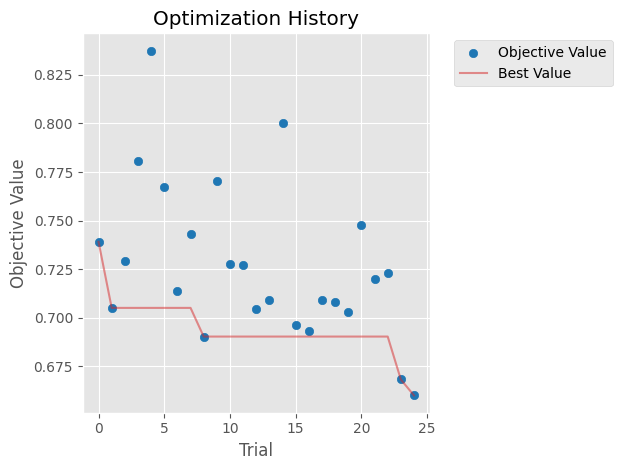

In [ ]:
#Visualize Optuna results
optuna.visualization.matplotlib.plot_optimization_history(study)

plt.title("Optimization History")
plt.show()

/tmp/ipykernel_681/429335526.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(study)


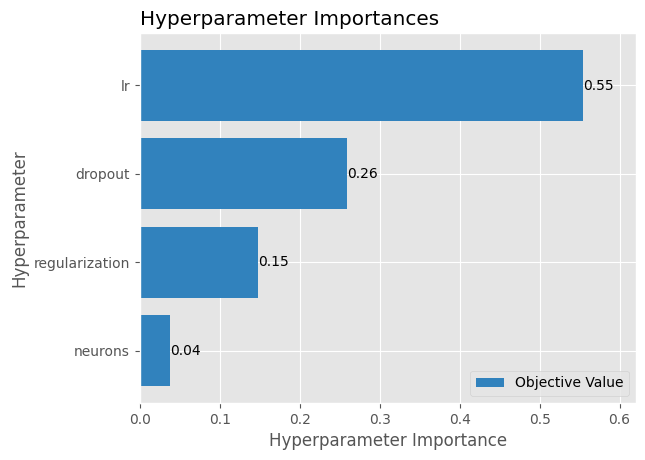

In [ ]:
optuna.visualization.matplotlib.plot_param_importances(study)
plt.show()

/tmp/ipykernel_681/1587980798.py:1: ExperimentalWarning: optuna.visualization.matplotlib._parallel_coordinate.plot_parallel_coordinate is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_parallel_coordinate(study)


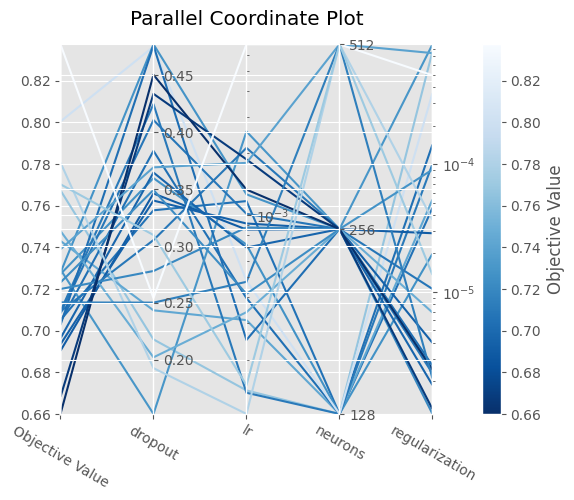

In [ ]:
optuna.visualization.matplotlib.plot_parallel_coordinate(study)

plt.show()

In [ ]:
# train the best model

model = CNN_tune(3, 0.45, 256).to(device)
loss_func = nn.CrossEntropyLoss()
optim = torch.optim.Adam(model.parameters(), lr = 0.0013, weight_decay = 2.4e-6)

# for Early Stopping
patience = 5
patience_counter = 0
best_val_loss = float('inf')
best_model_weights = None

# train loop
epochs = 50
for e in range(epochs):

  # ------------------ TRAINING PHASE ------------------
  avg_train_loss = train_model(model, optim)

  # ------------------ VALIDATION PHASE ------------------

  model.eval()
  val_loss = 0.0

  with torch.no_grad():
      for batch_x, batch_y in val_loader:
          batch_x, batch_y = batch_x.to(device), batch_y.to(device)
          y_pred = model(batch_x)
          loss = loss_func(y_pred, batch_y)
          val_loss += loss.item()

  avg_val_loss = val_loss / len(val_loader)

  # Print epoch progress
  print(f"Epoch {e+1:02d}/{epochs:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

  # Early stopping logic
  if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      patience_counter = 0
      # Save the best model parameters
      best_model_weights = model.state_dict().copy()
      print(f"--> Val loss improved! Saving best weights.")
  else:
      patience_counter += 1
      print(f"--> No improvement in val loss ({patience_counter}/{patience})")

  if patience_counter >= patience:
      print(f"\n[Early Stopping Triggered] Stopped early at epoch {e+1}.")
      break

# Restore best weights after training stops
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Loaded best model weights into model!")

Epoch 01/50 | Train Loss: 1.5308 | Val Loss: 1.1533
--> Val loss improved! Saving best weights.
Epoch 02/50 | Train Loss: 1.1262 | Val Loss: 0.9642
--> Val loss improved! Saving best weights.
Epoch 03/50 | Train Loss: 0.9575 | Val Loss: 0.9837
--> No improvement in val loss (1/5)
Epoch 04/50 | Train Loss: 0.8621 | Val Loss: 0.9634
--> Val loss improved! Saving best weights.
Epoch 05/50 | Train Loss: 0.7914 | Val Loss: 0.8328
--> Val loss improved! Saving best weights.
Epoch 06/50 | Train Loss: 0.7392 | Val Loss: 0.8939
--> No improvement in val loss (1/5)
Epoch 07/50 | Train Loss: 0.6917 | Val Loss: 0.7878
--> Val loss improved! Saving best weights.
Epoch 08/50 | Train Loss: 0.6443 | Val Loss: 0.7974
--> No improvement in val loss (1/5)
Epoch 09/50 | Train Loss: 0.5975 | Val Loss: 0.7093
--> Val loss improved! Saving best weights.
Epoch 10/50 | Train Loss: 0.5532 | Val Loss: 0.6948
--> Val loss improved! Saving best weights.
Epoch 11/50 | Train Loss: 0.5253 | Val Loss: 0.7795
--> No im

In [ ]:
#evaluation on train data
train_acc = eval_model(model, train_loader)
print(f"train accuracy -> {train_acc}")

#evaluation on val data
val_acc = eval_model(model, val_loader)
print(f"validation accuracy -> {val_acc}")


train accuracy -> 0.90655
validation accuracy -> 0.7617


reduced overfitting

- further reduction in overfitting requires more training data, which is not possible at this moment. So, data augmentation can be very helpful if you don't have any more data and want to improve the model performance by generating synthetic data by variations from your original dataset

- try transfer learning